# Titanic Survival Prediction

In [ ]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load the dataset

In [ ]:
# load the dataset
dataset = pd.read_csv('/content/Titanic-Dataset.csv')
dataset.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Data Cleaning

In [ ]:
# get info on dataset
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
# check for missing values
dataset.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
# check for duplicates
dataset.nunique()

,0
PassengerId,891
Survived,2
Pclass,3
Name,891
Sex,2
Age,88
SibSp,7
Parch,7
Ticket,681
Fare,248


In [ ]:
# handling missing values
from sklearn.impute import SimpleImputer

#  replacing missing age value with the median
imputer = SimpleImputer(strategy='median')
dataset['Age'] = imputer.fit_transform(dataset[['Age']])

# remove Cabin Column
dataset.drop('Cabin', axis=1, inplace=True)

# remove Embarked Column
dataset.drop('Embarked', axis=1, inplace=True)

# remove Name Column
dataset.drop('Name', axis=1, inplace=True)

# remove Ticket Column
dataset.drop('Ticket', axis=1, inplace=True)

# remove PassengerId Column
dataset.drop('PassengerId', axis=1, inplace=True)

In [ ]:
dataset.isnull().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0


In [ ]:
# create family size column
# Create FamilySize feature
dataset['FamilySize'] = dataset['SibSp'] + dataset['Parch'] + 1

# Check the distribution of FamilySize
print(dataset[['SibSp', 'Parch', 'FamilySize']].head())

   SibSp  Parch  FamilySize
0      1      0           2
1      1      0           2
2      0      0           1
3      1      0           2
4      0      0           1


## Exploratory Data Analysis

### Univariate Analysis (Single Features)

- Understand the distribution of numerical and categorical features.
- Identify outliers, skewness, and common values.

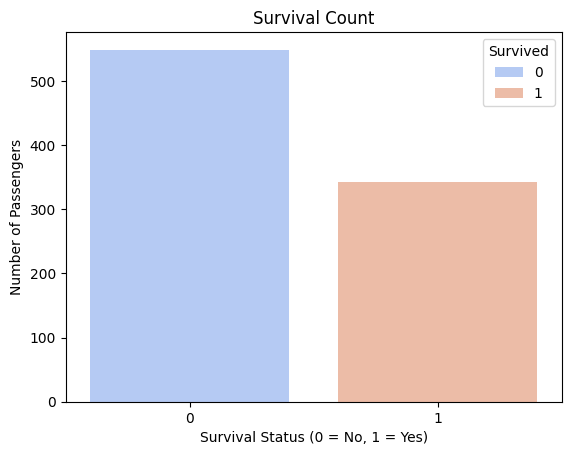

In [ ]:
# Plot Survival Count

sns.countplot(x='Survived', data=dataset, hue="Survived", palette="coolwarm")

# Add x-axis and y-axis labels
plt.xlabel("Survival Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.title('Survival Count')
plt.show()

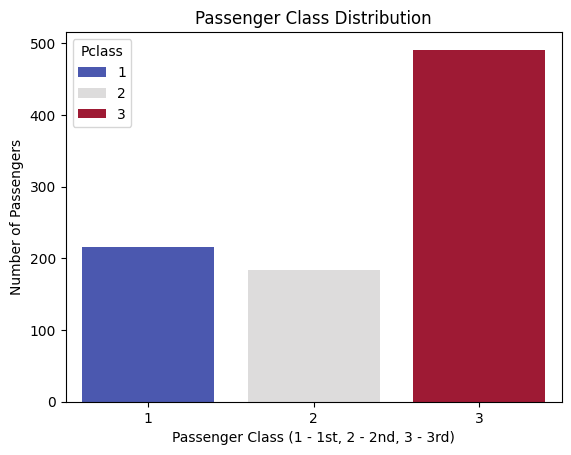

In [ ]:
# Plot class distribution
sns.countplot(x='Pclass', data=dataset, hue="Pclass", palette="coolwarm")

# Add x and y axis labels
plt.xlabel("Passenger Class (1 - 1st, 2 - 2nd, 3 - 3rd)")
plt.ylabel("Number of Passengers")

plt.title("Passenger Class Distribution")
plt.show()

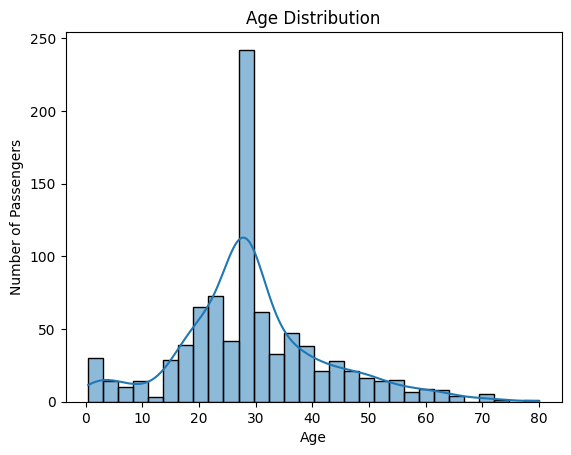

In [ ]:
# Plot Age distribution
sns.histplot(dataset['Age'], bins=30, kde=True)

# Add x-axis and y-axis labels
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.title("Age Distribution")
plt.show()

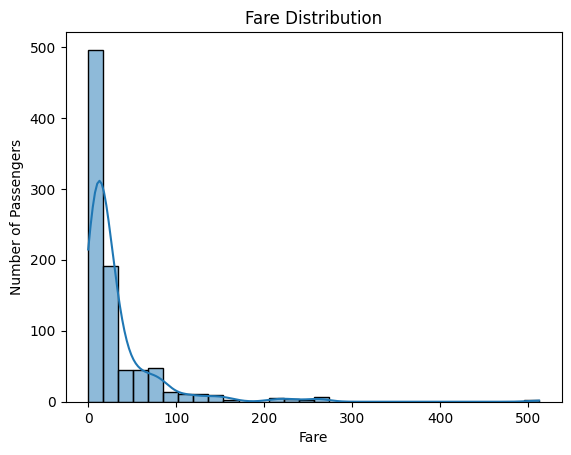

In [ ]:
# Plot Fare distribution
sns.histplot(dataset['Fare'], bins=30, kde=True)

# Add x-axis and y-axis labels
plt.xlabel("Fare")
plt.ylabel("Number of Passengers")

plt.title("Fare Distribution")
plt.show()

### Bivariate Analysis (Feature vs Target)

- Understand relationships between independent variables and survival.
- Identify which features might be good predictors.

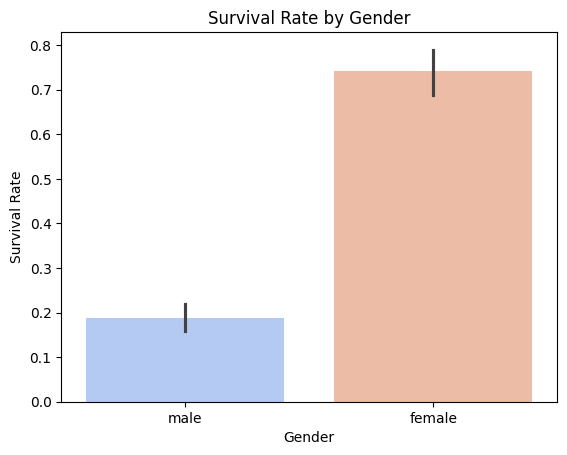

In [ ]:
# Survival rate by gender
sns.barplot(x='Sex', y='Survived', hue="Sex", data=dataset,  palette="coolwarm")

# Add x and y axis labels
plt.xlabel("Gender")
plt.ylabel("Survival Rate")

plt.title("Survival Rate by Gender")
plt.show()

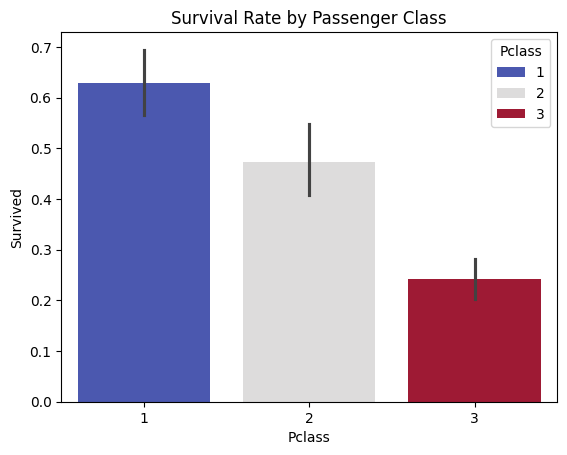

In [ ]:
# Survival rate by passenger class
sns.barplot(x='Pclass', y='Survived', hue="Pclass", data=dataset, palette="coolwarm")

# Add x-axis and y-axis labels
plt.xlabel("Pclass")
plt.ylabel("Survived")

plt.title("Survival Rate by Passenger Class")
plt.show()

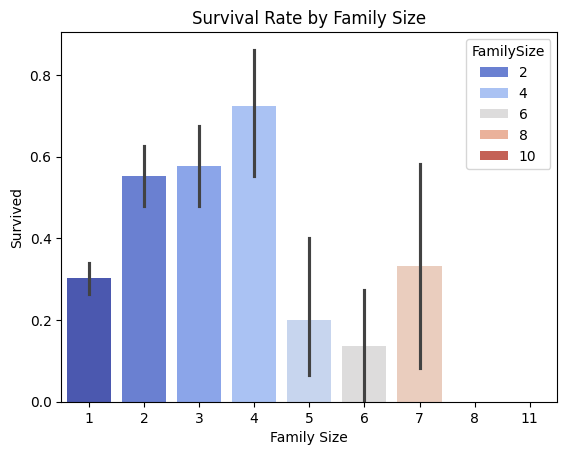

In [ ]:
sns.barplot(x='FamilySize', y='Survived', data=dataset, hue="FamilySize", palette="coolwarm")

# Add x and y axis labels
plt.xlabel("Family Size")
plt.ylabel("Survived")

plt.title("Survival Rate by Family Size")
plt.show()

## Matrix of Features and Dependent Variables

In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    891 non-null    int64  
 1   Pclass      891 non-null    int64  
 2   Sex         891 non-null    object 
 3   Age         891 non-null    float64
 4   SibSp       891 non-null    int64  
 5   Parch       891 non-null    int64  
 6   Fare        891 non-null    float64
 7   FamilySize  891 non-null    int64  
dtypes: float64(2), int64(5), object(1)
memory usage: 55.8+ KB


In [ ]:
# matrix of features

# Select columns 1 to 3 and the last column
X = pd.concat([dataset.iloc[:, 1:4], dataset.iloc[:, 6:]], axis=1).values

print(X)

[[3 'male' 22.0 7.25 2]
 [1 'female' 38.0 71.2833 2]
 [3 'female' 26.0 7.925 1]
 ...
 [3 'female' 28.0 23.45 4]
 [1 'male' 26.0 30.0 1]
 [3 'male' 32.0 7.75 1]]


In [ ]:
# dependent variable vector

y = dataset.iloc[:, 0].values

print(y)

[0 1 1 1 0 0 0 0 1 1 1 1 0 0 0 1 0 1 0 1 0 1 1 1 0 1 0 0 1 0 0 1 1 0 0 0 1
 0 0 1 0 0 0 1 1 0 0 1 0 0 0 0 1 1 0 1 1 0 1 0 0 1 0 0 0 1 1 0 1 0 0 0 0 0
 1 0 0 0 1 1 0 1 1 0 1 1 0 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 1 1 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 1 1 0 0 0 0 1 0 0 1 0 0 0 0 1 1 0 0 0 1 0
 0 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 1 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 1
 0 1 1 0 0 1 0 1 1 1 1 0 0 1 0 0 0 0 0 1 0 0 1 1 1 0 1 0 0 0 1 1 0 1 0 1 0
 0 0 1 0 1 0 0 0 1 0 0 1 0 0 0 1 0 0 0 1 0 0 0 0 0 1 1 0 0 0 0 0 0 1 1 1 1
 1 0 1 0 0 0 0 0 1 1 1 0 1 1 0 1 1 0 0 0 1 0 0 0 1 0 0 1 0 1 1 1 1 0 0 0 0
 0 0 1 1 1 1 0 1 0 1 1 1 0 1 1 1 0 0 0 1 1 0 1 1 0 0 1 1 0 1 0 1 1 1 1 0 0
 0 1 0 0 1 1 0 1 1 0 0 0 1 1 1 1 0 0 0 0 0 0 0 1 0 1 1 0 0 0 0 0 0 1 1 1 1
 1 0 0 0 0 1 1 0 0 0 1 1 0 1 0 0 0 1 0 1 1 1 0 1 1 0 0 0 0 1 1 0 0 0 0 0 0
 1 0 0 0 0 1 0 1 0 1 1 0 0 0 0 0 0 0 0 1 1 0 1 1 1 1 0 0 1 0 1 0 0 1 0 0 1
 1 1 1 1 1 1 0 0 0 1 0 1 0 1 1 0 1 0 0 0 0 0 0 0 0 1 0 0 1 1 0 0 0 0 0 1 0
 0 0 1 1 0 1 0 0 1 0 0 0 

## Encoding categorical data

In [ ]:
# Label Encoding Sex Column

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
X[:, 1] = le.fit_transform(X[:, 1])

print(X)

[[3 1 22.0 7.25 2]
 [1 0 38.0 71.2833 2]
 [3 0 26.0 7.925 1]
 ...
 [3 0 28.0 23.45 4]
 [1 1 26.0 30.0 1]
 [3 1 32.0 7.75 1]]


In [ ]:
print(X[0])

[3 1 22.0 7.25 2]


## Train Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
print(X[0])

[3 1 22.0 7.25 2]


## Feature Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
# Scale columns
X_train[:, 2:] = sc.fit_transform(X_train[:, 2:])
X_test[:, 2:] = sc.transform(X_test[:, 2:])

In [ ]:
print(X_train[0])

[3 0 -0.10684834689008824 -0.3316790433256366 0.6485339277429727]


In [ ]:
# scaling Pclass column [0]
# create a function that converts 1D column to 2D, scale them then return 1D column

def scale_column_fit_transform(column_X_train, column_X_test):
  column_2D_shape_X_train = column_X_train.reshape(-1, 1)
  column_2D_shape_X_test = column_X_test.reshape(-1, 1)

  scaled_column_Xtrain = sc.fit_transform(column_2D_shape_X_train)
  scaled_column_Xtest = sc.transform(column_2D_shape_X_test)

  column_1D_shape_X_train = scaled_column_Xtrain.flatten()
  column_1D_shape_X_test = scaled_column_Xtest.flatten()

  return column_1D_shape_X_train, column_1D_shape_X_test

X_train[:, 0], X_test[:, 0] = scale_column_fit_transform(X_train[:, 0], X_test[:, 0])

In [ ]:
print(X_train[0])

[0.819250590216178 0 -0.10684834689008824 -0.3316790433256366
 0.6485339277429727]


## Logistic Regression Model

### Training the Model

In [ ]:
# initialize and train the logistic regression model
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [ ]:
# Make predictions on the test set
y_pred = model.predict(X_test)

## Evaluate the Model

To analyze how well the model performs, we use:

1. Accuracy Score – Measures overall correctness.
2. Confusion Matrix – Shows correct vs incorrect classifications.
3. Classification Report – Provides precision, recall, and F1-score.

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Calculate accuracy score
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy Score:", accuracy)

Accuracy Score: 0.8212290502793296


In [ ]:
# Confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", conf_matrix)

Confusion Matrix:
 [[94 16]
 [16 53]]


In [ ]:
# Detailed classification report
class_report = classification_report(y_test, y_pred)
print("Classification Report:\n", class_report)

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.85      0.85       110
           1       0.77      0.77      0.77        69

    accuracy                           0.82       179
   macro avg       0.81      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179



## Random Forest Model

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=0)
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=0)

In [ ]:
# make predictions
rf_y_pred = rf_model.predict(X_test)

### Evaluate the Model

In [ ]:
# Accuracy
accuracy_rf = accuracy_score(y_test, rf_y_pred)
print(f"Random Forest Accuracy: {accuracy_rf:.4f}")

Random Forest Accuracy: 0.8324


In [ ]:
# Confusion matrix
conf_matrix_rf = confusion_matrix(y_test, rf_y_pred)
print("Confusion Matrix:\n", conf_matrix_rf)

Confusion Matrix:
 [[101   9]
 [ 21  48]]


In [ ]:
# Classification report
class_report_rf = classification_report(y_test, rf_y_pred)
print("Classification Report:\n", class_report_rf)

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.92      0.87       110
           1       0.84      0.70      0.76        69

    accuracy                           0.83       179
   macro avg       0.83      0.81      0.82       179
weighted avg       0.83      0.83      0.83       179

